# DP fine-tuning on chest X-rays: who pays the privacy cost?

In this notebook I explore **differentially private (DP) fine-tuning** on the NIH ChestX-ray14 dataset.

Main question: when we train with DP-SGD, does the accuracy loss hit all patients equally, or do some groups
(sex × age) lose more? And is it the **clipping** or the **noise** of DP-SGD that causes it?

Plan:
1. Extract features with two frozen backbones: **DINOv2-S** (generic) and **RAD-DINO** (pretrained on chest X-rays).
2. Train a linear classifier on top with DP-SGD (my own small implementation) for different ε.
3. Look at the AUC of each patient group, separate clipping from noise, and check who gets clipped.
4. Try different clip norms C.
5. A small DP-LoRA experiment: fine-tune DINOv2-S itself with Opacus.


In [1]:
!pip install -q opacus

In [2]:
import os, glob, math, time
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from PIL import Image
import torch
import torch.nn as nn
import torch.nn.functional as F
from torch.utils.data import Dataset, DataLoader
from sklearn.metrics import roc_auc_score
from transformers import AutoModel, AutoImageProcessor
import warnings
warnings.filterwarnings('ignore')

device = 'cuda' if torch.cuda.is_available() else 'cpu'
print('device:', device)

SEED = 0
USE_RADDINO = True        # set to False to skip RAD-DINO (feature extraction becomes ~3x faster)
MIN_POS = 10              # a finding needs at least 10 positive cases to be used in an AUC
WORK_DIR = '/kaggle/working'

FINDINGS = ['Atelectasis', 'Cardiomegaly', 'Consolidation', 'Edema', 'Effusion', 'Emphysema', 'Fibrosis',
            'Hernia', 'Infiltration', 'Mass', 'Nodule', 'Pleural_Thickening', 'Pneumonia', 'Pneumothorax']
IMNET_MEAN, IMNET_STD = [0.485, 0.456, 0.406], [0.229, 0.224, 0.225]

device: cuda


## 1. Data

I keep **one random image per patient**. So one training example = one patient, and ε protects patients
(not just single images). This also makes the data smaller and feature extraction faster.

Patients are split into train 65% / public 5% / val 10% / test 20%. The small *public* part is treated as
non-private data: I only use it to standardize the features, so that step costs no privacy.

In [3]:
csv_path = glob.glob('/kaggle/input/**/Data_Entry_2017.csv', recursive=True)[0]
data_dir = os.path.dirname(csv_path)
df = pd.read_csv(csv_path)

# image name -> full path (the images are spread over 12 folders)
paths = {}
for p in glob.glob(data_dir + '/images_*/images/*.png'):
    paths[os.path.basename(p)] = p
print(len(df), 'rows,', len(paths), 'images found')

df = df[df['Image Index'].isin(paths)]
df['path'] = df['Image Index'].map(paths)
df = df.rename(columns={'Patient ID': 'patient', 'Patient Age': 'age', 'Patient Gender': 'sex'})
df = df[(df.age > 0) & (df.age <= 100)]          # a few ages are typos (e.g. 414)

for f in FINDINGS:
    df[f] = df['Finding Labels'].str.contains(f, regex=False).astype(int)
df['n_findings'] = df[FINDINGS].sum(axis=1)

df['age_group'] = pd.cut(df.age, [0, 40, 60, 101], right=False, labels=['<40', '40-59', '60+'])
df['group'] = df.sex + ' ' + df.age_group.astype(str)

# one random image per patient, then split the patients
df = df.sample(frac=1, random_state=SEED).drop_duplicates('patient').reset_index(drop=True)
rng = np.random.RandomState(SEED)
df['split'] = rng.choice(['train', 'public', 'val', 'test'], size=len(df), p=[0.65, 0.05, 0.10, 0.20])

print(df.split.value_counts())
print(pd.crosstab(df.group, df.split))
print('patients with at least one finding:', round((df.n_findings > 0).mean(), 3))

112120 rows, 112120 images found
split
train     20149
test       6137
val        3047
public     1469
Name: count, dtype: int64
split    public  test  train  val
group                            
F 40-59     285  1329   4238  630
F 60+       134   516   1811  292
F <40       227  1001   3243  467
M 40-59     301  1334   4593  707
M 60+       228   853   2726  398
M <40       294  1104   3538  553
patients with at least one finding: 0.329


## 2. Feature extraction (frozen backbones)

Each image is resized to 224 px for DINOv2-S and to 518 px for RAD-DINO (its native size).
I also keep the 224 px images in memory for the LoRA part at the end.
Features are saved to `/kaggle/working`, so after a kernel restart this cell just loads them.

In [4]:
dino = AutoModel.from_pretrained('facebook/dinov2-small').to(device).eval()
if USE_RADDINO:
    rad = AutoModel.from_pretrained('microsoft/rad-dino').to(device).eval()
    rad_proc = AutoImageProcessor.from_pretrained('microsoft/rad-dino')
    RAD_MEAN, RAD_STD = rad_proc.image_mean, rad_proc.image_std
RAD_SIZE = 518 if USE_RADDINO else 224


def normalize(x, mean, std):
    # x: uint8 images (B, H, W) -> float (B, 3, H, W)
    x = x.float() / 255
    x = x.unsqueeze(1).repeat(1, 3, 1, 1)
    mean = torch.tensor(mean, device=x.device).view(1, 3, 1, 1)
    std = torch.tensor(std, device=x.device).view(1, 3, 1, 1)
    return (x - mean) / std


class XrayDataset(Dataset):
    def __init__(self, paths):
        self.paths = list(paths)

    def __len__(self):
        return len(self.paths)

    def __getitem__(self, i):
        img = Image.open(self.paths[i]).convert('L')
        small = np.array(img.resize((224, 224), Image.BICUBIC))
        big = np.array(img.resize((RAD_SIZE, RAD_SIZE), Image.BICUBIC))
        return small, big

config.json:   0%|          | 0.00/547 [00:00<?, ?B/s]

model.safetensors: reconstructing file:   0%|          |  0.00B / 88.2MB            

model.safetensors: downloading bytes:           |  0.00B            

Loading weights:   0%|          | 0/223 [00:00<?, ?it/s]

config.json:   0%|          | 0.00/879 [00:00<?, ?B/s]

model.safetensors: reconstructing file:   0%|          |  0.00B /  346MB            

model.safetensors: downloading bytes:           |  0.00B            

Loading weights:   0%|          | 0/223 [00:00<?, ?it/s]

preprocessor_config.json:   0%|          | 0.00/756 [00:00<?, ?B/s]

In [5]:
N = len(df)
if os.path.exists(f'{WORK_DIR}/feats_dino.npy'):
    print('loading saved features')
    images = np.load(f'{WORK_DIR}/images224.npy')
    feats_dino = np.load(f'{WORK_DIR}/feats_dino.npy')
    if USE_RADDINO:
        feats_rad = np.load(f'{WORK_DIR}/feats_rad.npy')
else:
    images = np.zeros((N, 224, 224), dtype=np.uint8)
    feats_dino = np.zeros((N, 384), dtype=np.float32)
    feats_rad = np.zeros((N, 768), dtype=np.float32)
    loader = DataLoader(XrayDataset(df.path), batch_size=64, num_workers=4)
    start = time.time()
    i = 0
    with torch.no_grad(), torch.autocast('cuda', dtype=torch.float16):
        for b, (small, big) in enumerate(loader):
            n = len(small)
            images[i:i + n] = small.numpy()
            x = normalize(small.to(device), IMNET_MEAN, IMNET_STD)
            feats_dino[i:i + n] = dino(pixel_values=x).pooler_output.float().cpu().numpy()
            if USE_RADDINO:
                x = normalize(big.to(device), RAD_MEAN, RAD_STD)
                feats_rad[i:i + n] = rad(pixel_values=x).pooler_output.float().cpu().numpy()
            i += n
            if b % 100 == 0:
                print(f'{i}/{N} images, {time.time() - start:.0f} s')
    print(f'done in {(time.time() - start) / 60:.1f} min')
    np.save(f'{WORK_DIR}/images224.npy', images)
    np.save(f'{WORK_DIR}/feats_dino.npy', feats_dino)
    if USE_RADDINO:
        np.save(f'{WORK_DIR}/feats_rad.npy', feats_rad)

64/30802 images, 18 s
6464/30802 images, 309 s
12864/30802 images, 588 s
19264/30802 images, 865 s
25664/30802 images, 1141 s
done in 22.7 min


## 3. DP-SGD for a linear head

For a linear multi-label head with BCE loss, the gradient of one patient is
$g_i = (p_i - y_i)\,x_i^\top$ (with a 1 appended to $x_i$ for the bias). So its norm is simply

$$\|g_i\| = \|p_i - y_i\| \cdot \|x_i\|$$

i.e. **(prediction error) × (feature norm)**. Because of this I don't need Opacus here: I can compute every
per-sample gradient norm directly, clip, add Gaussian noise, and step. I only use Opacus to compute the
noise multiplier σ for a given ε (δ = 1e-5).

DP-SGD steps: Poisson sampling of a batch → clip each patient's gradient to norm C → sum → add noise N(0, σ²C²) → Adam step.

In [6]:
from opacus.accountants.utils import get_noise_multiplier

DELTA = 1e-5
LR_LIST = [0.001, 0.003, 0.01]     # learning rates to try (chosen on the validation set)
EPOCHS = 30
BATCH = 2048

Y = df[FINDINGS].values.astype(np.float32)
groups = df.group.values
train_idx = np.where(df.split == 'train')[0]
pub_idx = np.where(df.split == 'public')[0]
val_idx = np.where(df.split == 'val')[0]
test_idx = np.where(df.split == 'test')[0]
GROUP_NAMES = sorted(df.group.unique())
YOUNG = [g for g in GROUP_NAMES if '<40' in g]
OLD = [g for g in GROUP_NAMES if '60+' in g]


def standardize(X):
    # mean / std from the public split only; dividing by sqrt(dim) makes ||x|| about 1
    mu = X[pub_idx].mean(0)
    sd = X[pub_idx].std(0) + 1e-6
    return ((X - mu) / sd / math.sqrt(X.shape[1])).astype(np.float32)


def train_head(X, eps=None, C=1.0, lr=0.01, clip=True, noise=True, seed=0, idx=None, track=False):
    # eps=None -> normal (non-private) training
    torch.manual_seed(seed)
    if idx is None:
        idx = train_idx
    if eps is None:
        clip, noise = False, False
    x = torch.tensor(X[idx], device=device)
    x = torch.cat([x, torch.ones(len(x), 1, device=device)], dim=1)     # bias column
    y = torch.tensor(Y[idx], device=device)
    n, d = x.shape
    q = BATCH / n
    steps = int(EPOCHS / q)
    sigma = 0
    if noise:
        sigma = get_noise_multiplier(target_epsilon=eps, target_delta=DELTA, sample_rate=q,
                                     steps=steps, accountant='rdp')

    W = torch.zeros(len(FINDINGS), d, device=device, requires_grad=True)
    opt = torch.optim.Adam([W], lr=lr)
    xnorm = x.norm(dim=1)
    seen = torch.zeros(n, device=device)
    clipped = torch.zeros(n, device=device)
    kept = torch.zeros(n, device=device)
    error = torch.zeros(n, device=device)

    for step in range(steps):
        batch = torch.rand(n, device=device) < q             # Poisson sampling
        xb, yb = x[batch], y[batch]
        with torch.no_grad():
            err = torch.sigmoid(xb @ W.T) - yb                # p - y
            gnorm = err.norm(dim=1) * xnorm[batch]            # per-sample gradient norm
            factor = torch.ones_like(gnorm)
            if clip:
                factor = torch.clamp(C / gnorm, max=1.0)
            grad = (err * factor[:, None]).T @ xb             # sum of clipped gradients
            if noise:
                grad += torch.randn_like(grad) * sigma * C
            if track:
                seen[batch] += 1
                clipped[batch] += (factor < 1).float()
                kept[batch] += factor
                error[batch] += err.norm(dim=1)
        W.grad = grad / (q * n)
        opt.step()

    info = {'sigma': sigma}
    if track:
        seen = seen.clamp(min=1)
        info['clip_rate'] = (clipped / seen).cpu().numpy()
        info['kept'] = (kept / seen).cpu().numpy()            # fraction of the gradient that survives clipping
        info['error'] = (error / seen).cpu().numpy()
        info['feat_norm'] = xnorm.cpu().numpy()
    return W.detach(), info


def predict(W, X, idx):
    x = torch.tensor(X[idx], device=device)
    x = torch.cat([x, torch.ones(len(x), 1, device=device)], dim=1)
    with torch.no_grad():
        return torch.sigmoid(x @ W.T).cpu().numpy()


def mean_auc(y, p, cols=None):
    if cols is None:
        cols = range(y.shape[1])
    aucs = [roc_auc_score(y[:, k], p[:, k]) for k in cols if MIN_POS <= y[:, k].sum() <= len(y) - MIN_POS]
    return np.mean(aucs)


# for the group AUCs I use the same findings in every group (enough positives in each test group)
y_test, g_test = Y[test_idx], groups[test_idx]
COMMON = [k for k in range(len(FINDINGS)) if all(y_test[g_test == g, k].sum() >= MIN_POS for g in GROUP_NAMES)]
print('findings used for group AUCs:', [FINDINGS[k] for k in COMMON])


def evaluate_probs(p, idx=test_idx):
    y, g = Y[idx], groups[idx]
    res = {'overall': mean_auc(y, p)}
    for name in GROUP_NAMES:
        res[name] = mean_auc(y[g == name], p[g == name], COMMON)
    res['worst'] = min(res[name] for name in GROUP_NAMES)
    res['age_gap'] = np.mean([res[g] for g in YOUNG]) - np.mean([res[g] for g in OLD])   # young minus old
    return res


def evaluate(W, X):
    return evaluate_probs(predict(W, X, test_idx))


features = {'DINOv2-S': standardize(feats_dino)}
if USE_RADDINO:
    features['RAD-DINO'] = standardize(feats_rad)

# quick sanity check: non-private probe
for name, X in features.items():
    W, _ = train_head(X)
    print(f'{name}: non-private test AUC = {evaluate(W, X)["overall"]:.4f}')

findings used for group AUCs: ['Atelectasis', 'Cardiomegaly', 'Consolidation', 'Effusion', 'Infiltration', 'Mass', 'Nodule']
DINOv2-S: non-private test AUC = 0.6711
RAD-DINO: non-private test AUC = 0.6985


## 4. Experiment 1 — AUC per group for different ε

For each ε I pick the clip norm C and the learning rate on the validation set, then train with 3 seeds.
Note: `overall` uses all findings, the group columns use only the findings with enough cases in every group.
`age_gap` = mean AUC of the <40 groups − mean AUC of the 60+ groups.

In [7]:
EPS_LIST = [None, 8, 2, 1]          # None = non-private
C_LIST = [0.3, 0.5, 1.0]
SEEDS = [0, 1, 2]


def pick_params(X, eps, C_list=C_LIST, clip=True, noise=True, idx=None):
    # try every (C, lr) and keep the one with the best validation AUC
    if eps is None:
        C_list = [1.0]          # C does not matter without clipping
    best, best_auc = None, -1
    for C in C_list:
        for lr in LR_LIST:
            W, _ = train_head(X, eps=eps, C=C, lr=lr, clip=clip, noise=noise, idx=idx)
            auc = mean_auc(Y[val_idx], predict(W, X, val_idx))
            if auc > best_auc:
                best, best_auc = (C, lr), auc
    return best


start = time.time()
rows = []
best = {}
for name, X in features.items():
    for eps in EPS_LIST:
        C, lr = pick_params(X, eps)
        best[(name, eps)] = (C, lr)
        for seed in SEEDS:
            W, _ = train_head(X, eps=eps, C=C, lr=lr, seed=seed)
            r = evaluate(W, X)
            r['backbone'], r['eps'], r['C'], r['lr'] = name, ('inf' if eps is None else eps), C, lr
            rows.append(r)
print(f'{time.time() - start:.0f} s')

exp1 = pd.DataFrame(rows).groupby(['backbone', 'eps'], sort=False).mean(numeric_only=True)
print(exp1[['C', 'lr', 'overall', 'worst', 'age_gap'] + GROUP_NAMES].round(3))

print('\nAUC drop compared to non-private (positive = worse):')
for name in features:
    print(name)
    print((exp1.loc[(name, 'inf'), GROUP_NAMES] - exp1.loc[name][GROUP_NAMES]).round(3))

60 s
                C    lr  overall  worst  age_gap  F 40-59  F 60+  F <40  \
backbone eps                                                              
DINOv2-S inf  1.0  0.01    0.669  0.670    0.019    0.698  0.670  0.693   
         8    0.3  0.01    0.676  0.639    0.043    0.644  0.639  0.687   
         2    0.5  0.01    0.673  0.639    0.042    0.640  0.640  0.685   
         1    0.5  0.01    0.667  0.630    0.046    0.630  0.636  0.677   
RAD-DINO inf  1.0  0.01    0.698  0.705    0.073    0.755  0.709  0.810   
         8    0.3  0.01    0.728  0.682    0.089    0.737  0.701  0.807   
         2    0.3  0.01    0.737  0.697    0.081    0.737  0.705  0.808   
         1    0.3  0.01    0.730  0.693    0.081    0.730  0.700  0.802   

              M 40-59  M 60+  M <40  
backbone eps                         
DINOv2-S inf    0.724  0.701  0.716  
         8      0.686  0.658  0.697  
         2      0.682  0.663  0.702  
         1      0.667  0.646  0.696  
RAD-DINO inf    

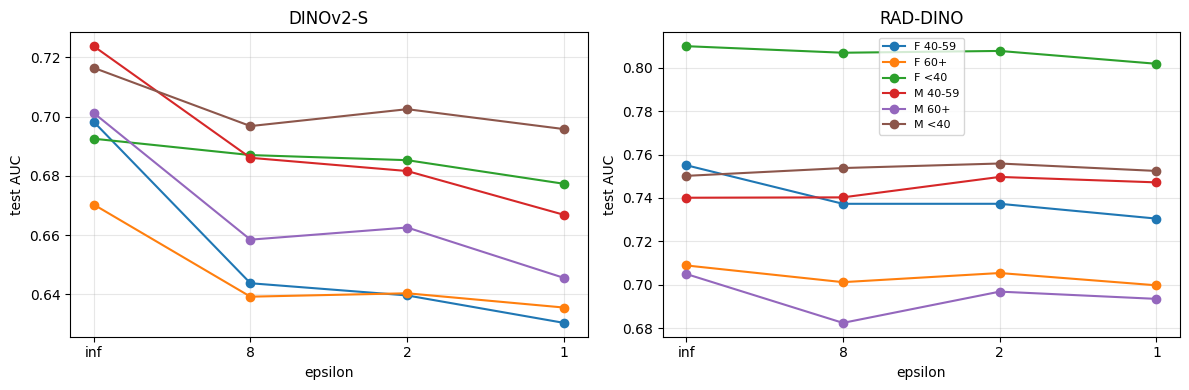

In [8]:
fig, axes = plt.subplots(1, len(features), figsize=(6 * len(features), 4), squeeze=False)
for ax, name in zip(axes[0], features):
    t = exp1.loc[name]
    for g in GROUP_NAMES:
        ax.plot([str(e) for e in t.index], t[g], marker='o', label=g)
    ax.set_title(name)
    ax.set_xlabel('epsilon')
    ax.set_ylabel('test AUC')
    ax.grid(alpha=0.3)
axes[0, -1].legend(fontsize=8)
plt.tight_layout()
plt.show()

## 5. Experiment 2 — clipping or noise?

At ε = 2 I train three versions with the same C: only clipping (no noise), only noise (no clipping), and
full DP. The first two are not private; they just tell me which part of DP-SGD causes the damage.
The learning rate is chosen again for each version.

In [9]:
rows = []
for name, X in features.items():
    C = best[(name, 2)][0]
    base = exp1.loc[(name, 'inf')]
    for variant, clip, noise in [('clip only', True, False), ('noise only', False, True), ('full DP', True, True)]:
        _, lr = pick_params(X, 2, C_list=[C], clip=clip, noise=noise)
        res = []
        for seed in SEEDS:
            W, _ = train_head(X, eps=2, C=C, lr=lr, clip=clip, noise=noise, seed=seed)
            res.append(evaluate(W, X))
        res = pd.DataFrame(res).mean()
        rows.append({'backbone': name, 'variant': variant, 'C': C,
                     'overall drop': base['overall'] - res['overall'],
                     'worst-group drop': base['worst'] - res['worst'],
                     'extra age gap': res['age_gap'] - base['age_gap']})
exp2 = pd.DataFrame(rows)
print(exp2.round(4).to_string(index=False))

backbone    variant   C  overall drop  worst-group drop  extra age gap
DINOv2-S  clip only 0.5       -0.0103            0.0161         0.0037
DINOv2-S noise only 0.5        0.0000            0.0038         0.0117
DINOv2-S    full DP 0.5       -0.0039            0.0314         0.0237
RAD-DINO  clip only 0.3       -0.0009            0.0372         0.0129
RAD-DINO noise only 0.3       -0.0002            0.0012         0.0053
RAD-DINO    full DP 0.3       -0.0396            0.0081         0.0076


## 6. Experiment 3 — who gets clipped?

One DP run per backbone (ε = 2). For every training patient I record how often their gradient was clipped,
how much of it was kept on average, their prediction error ‖p − y‖ and their feature norm ‖x‖.

In [10]:
train_info = df.iloc[train_idx][['group', 'n_findings']].reset_index(drop=True)
train_info['n_findings'] = train_info.n_findings.clip(upper=3)        # 3 means "3 or more"
cols = ['clip_rate', 'kept', 'error', 'feat_norm']

for name, X in features.items():
    C, lr = best[(name, 2)]
    W, info = train_head(X, eps=2, C=C, lr=lr, track=True)
    t = train_info.copy()
    for c in cols:
        t[c] = info[c]
    print(f'===== {name} (eps=2, C={C}) =====')
    print('by number of findings:')
    print(t.groupby('n_findings')[cols].mean().round(3))
    print('by group:')
    print(t.groupby('group')[cols].mean().round(3))
    print()

===== DINOv2-S (eps=2, C=0.5) =====
by number of findings:
            clip_rate   kept  error  feat_norm
n_findings                                    
0               0.671  0.619  0.846      1.380
1               1.000  0.308  1.300      1.419
2               1.000  0.236  1.557      1.471
3               1.000  0.197  1.751      1.533
by group:
         clip_rate   kept  error  feat_norm
group                                      
F 40-59      0.770  0.518  0.992      1.389
F 60+        0.865  0.427  1.167      1.426
F <40        0.730  0.544  0.980      1.436
M 40-59      0.781  0.518  0.993      1.365
M 60+        0.872  0.427  1.176      1.415
M <40        0.721  0.552  0.968      1.401

===== RAD-DINO (eps=2, C=0.3) =====
by number of findings:
            clip_rate   kept  error  feat_norm
n_findings                                    
0               0.911  0.410  0.803      1.408
1               1.000  0.188  1.181      1.420
2               1.000  0.152  1.397      1.441
3 

## 7. Experiment 4 — changing the clip norm C

At ε = 2: small C → strong clipping, large C → more noise (the noise is σ·C).
`sick weight` = average kept fraction of patients with a finding / that of healthy patients
(1 means clipping treats them equally).

70 s
backbone    C   lr  overall  worst  extra age gap  sick weight
DINOv2-S 0.10 0.01   0.6572 0.6169         0.0351       0.2362
DINOv2-S 0.20 0.01   0.6642 0.6244         0.0290       0.2966
DINOv2-S 0.30 0.01   0.6690 0.6303         0.0253       0.3525
DINOv2-S 0.50 0.01   0.6730 0.6389         0.0237       0.4565
DINOv2-S 0.75 0.01   0.6722 0.6429         0.0253       0.5812
DINOv2-S 1.00 0.01   0.6694 0.6443         0.0249       0.7041
DINOv2-S 1.50 0.01   0.6591 0.6449         0.0229       0.8918
DINOv2-S 2.00 0.01   0.6495 0.6428         0.0225       0.9632
DINOv2-S 3.00 0.01   0.6415 0.6362         0.0235       0.9977
DINOv2-S 5.00 0.01   0.6270 0.6215         0.0226       1.0000
RAD-DINO 0.10 0.01   0.7363 0.6936         0.0060       0.3865
RAD-DINO 0.20 0.01   0.7368 0.6945         0.0065       0.3990
RAD-DINO 0.30 0.01   0.7374 0.6968         0.0076       0.4265
RAD-DINO 0.50 0.01   0.7364 0.7012         0.0102       0.5002
RAD-DINO 0.75 0.01   0.7322 0.7048         0.0121 

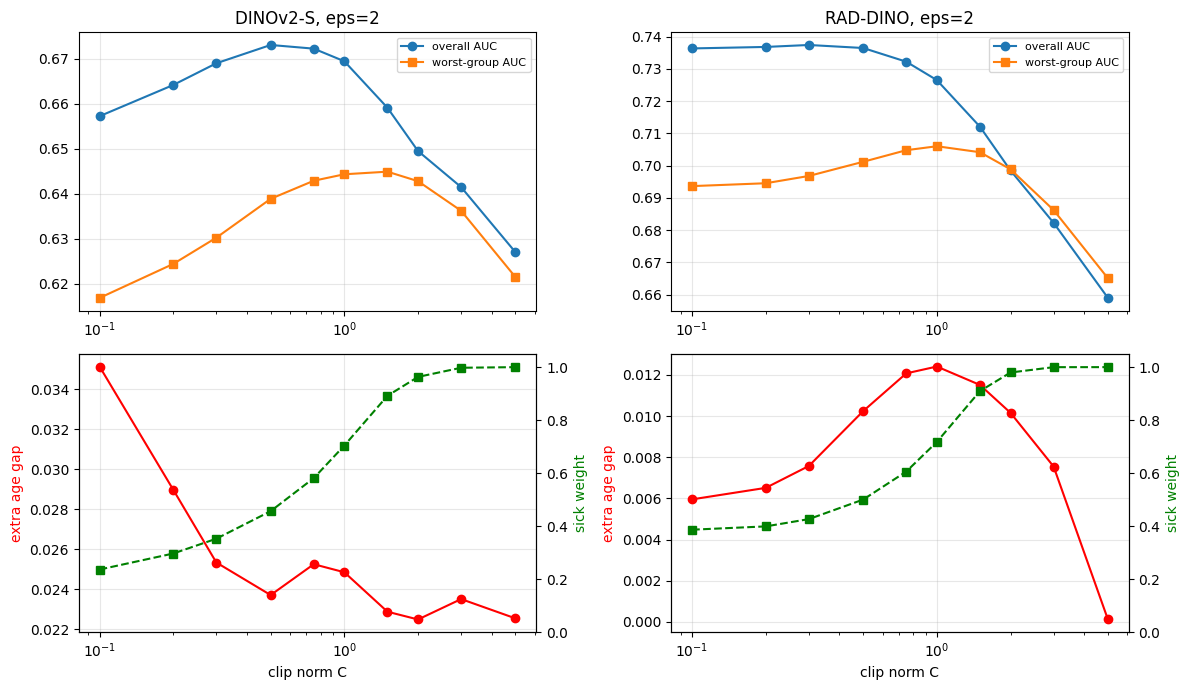

In [15]:
C_SWEEP = [0.1, 0.2, 0.3, 0.5, 0.75, 1.0, 1.5, 2.0, 3.0, 5.0]
sick = df.n_findings.values[train_idx] > 0

rows = []
start = time.time()
for name, X in features.items():
    base_gap = exp1.loc[(name, 'inf'), 'age_gap']
    for C in C_SWEEP:
        _, lr = pick_params(X, 2, C_list=[C])
        res = []
        for seed in SEEDS:
            W, info = train_head(X, eps=2, C=C, lr=lr, seed=seed, track=(seed == 0))
            res.append(evaluate(W, X))
            if seed == 0:
                sick_weight = info['kept'][sick].mean() / info['kept'][~sick].mean()
        res = pd.DataFrame(res).mean()
        rows.append({'backbone': name, 'C': C, 'lr': lr, 'overall': res['overall'], 'worst': res['worst'],
                     'extra age gap': res['age_gap'] - base_gap, 'sick weight': sick_weight})
print(f'{time.time() - start:.0f} s')
exp4 = pd.DataFrame(rows)
print(exp4.round(4).to_string(index=False))

fig, axes = plt.subplots(2, len(features), figsize=(6 * len(features), 7), squeeze=False)
for j, name in enumerate(features):
    t = exp4[exp4.backbone == name]
    axes[0, j].plot(t.C, t.overall, 'o-', label='overall AUC')
    axes[0, j].plot(t.C, t.worst, 's-', label='worst-group AUC')
    axes[0, j].set_title(f'{name}, eps=2')
    axes[1, j].plot(t.C, t['extra age gap'], 'o-', color='red')
    axes[1, j].set_ylabel('extra age gap', color='red')
    axes[1, j].set_xlabel('clip norm C')
    ax2 = axes[1, j].twinx()                      # second y-axis for the sick weight
    ax2.plot(t.C, t['sick weight'], 's--', color='green')
    ax2.set_ylabel('sick weight', color='green')
    ax2.set_ylim(0, 1.05)
    axes[0, j].legend(fontsize=8)
    for ax in axes[:, j]:
        ax.set_xscale('log')
        ax.grid(alpha=0.3)
plt.tight_layout()
plt.savefig('c_sweep.png', dpi=150)
plt.show()

## 8. Experiment 5 — DP-LoRA (small)

Here the backbone itself is fine-tuned. I add LoRA (rank 8) to the query and value layers of DINOv2-S and train
LoRA + head with DP-SGD from **Opacus**. Per-sample gradients through a ViT are slow on a T4, so this part
uses a subset of 6000 training patients and 3 epochs (~4 min per run). For a fair comparison I also train
the frozen DINOv2-S head on the same 6000 patients.

In [12]:
from opacus import PrivacyEngine
from opacus.utils.batch_memory_manager import BatchMemoryManager

LORA_N = 6000
lora_idx = np.random.RandomState(SEED).choice(train_idx, min(LORA_N, len(train_idx)), replace=False)
mu_dino = feats_dino[pub_idx].mean(0)
sd_dino = feats_dino[pub_idx].std(0) + 1e-6


class LoRA(nn.Module):
    # output = frozen linear(x) + B(A(x)) * scale ; B starts at zero, so at the start nothing changes
    def __init__(self, linear, r=8, alpha=16):
        super().__init__()
        self.linear = linear
        self.A = nn.Linear(linear.in_features, r, bias=False)
        self.B = nn.Linear(r, linear.out_features, bias=False)
        nn.init.zeros_(self.B.weight)
        self.scale = alpha / r

    def forward(self, x):
        return self.linear(x) + self.B(self.A(x)) * self.scale


def add_lora(model):
    for p in model.parameters():
        p.requires_grad = False
    for layer in model.encoder.layer:
        att = layer.attention
        if hasattr(att, 'q_proj'):              # newer transformers versions
            att.q_proj = LoRA(att.q_proj)
            att.v_proj = LoRA(att.v_proj)
        else:                                   # older versions
            att.attention.query = LoRA(att.attention.query)
            att.attention.value = LoRA(att.attention.value)
    return model


class LoRAClassifier(nn.Module):
    def __init__(self):
        super().__init__()
        self.backbone = add_lora(AutoModel.from_pretrained('facebook/dinov2-small'))
        self.register_buffer('mu', torch.tensor(mu_dino))
        self.register_buffer('sd', torch.tensor(sd_dino))
        self.head = nn.Linear(384, len(FINDINGS))

    def forward(self, x):
        x = normalize(x, IMNET_MEAN, IMNET_STD)
        h = self.backbone(pixel_values=x).pooler_output
        h = (h - self.mu) / self.sd / math.sqrt(384)      # same standardization as the frozen head
        return self.head(h)


class ImageDataset(Dataset):
    def __init__(self, idx):
        self.idx = idx

    def __len__(self):
        return len(self.idx)

    def __getitem__(self, i):
        j = self.idx[i]
        return torch.from_numpy(images[j]), torch.from_numpy(Y[j])


def train_lora(eps, epochs=3, lr=1e-3, C=1.0):
    torch.manual_seed(SEED)
    model = LoRAClassifier().to(device)
    opt = torch.optim.Adam([p for p in model.parameters() if p.requires_grad], lr=lr)
    loader = DataLoader(ImageDataset(lora_idx), batch_size=256, shuffle=True)
    engine = PrivacyEngine(accountant='rdp')
    if eps is None:   # non-private: same code, but no noise and no real clipping
        model, opt, loader = engine.make_private(module=model, optimizer=opt, data_loader=loader,
                                                 noise_multiplier=0.0, max_grad_norm=1e6)
    else:
        model, opt, loader = engine.make_private_with_epsilon(module=model, optimizer=opt, data_loader=loader,
                                                              target_epsilon=eps, target_delta=DELTA,
                                                              epochs=epochs, max_grad_norm=C)
    print(f'eps={eps}, sigma={opt.noise_multiplier:.3f}')
    start = time.time()
    model.train()
    for epoch in range(epochs):
        with BatchMemoryManager(data_loader=loader, max_physical_batch_size=64, optimizer=opt) as batches:
            for x, y in batches:
                x, y = x.to(device), y.to(device)
                loss = F.binary_cross_entropy_with_logits(model(x), y, reduction='none').sum(1).mean()
                opt.zero_grad()
                loss.backward()
                opt.step()
        print(f'  epoch {epoch + 1}: loss {loss.item():.3f}, {time.time() - start:.0f} s')
    if eps is not None:
        print(f'  epsilon spent: {engine.get_epsilon(DELTA):.2f}')
    return model


def predict_lora(model, idx):
    model.eval()
    probs = []
    with torch.no_grad():
        for x, _ in DataLoader(ImageDataset(idx), batch_size=128):
            probs.append(torch.sigmoid(model(x.to(device))).cpu().numpy())
    return np.concatenate(probs)

In [13]:
rows = []
X = features['DINOv2-S']
for eps in [None, 8]:
    # frozen backbone + DP head, same 6000 patients
    C, lr = pick_params(X, eps, idx=lora_idx)
    W, _ = train_head(X, eps=eps, C=C, lr=lr, idx=lora_idx)
    r = evaluate(W, X)
    r['model'], r['eps'] = 'frozen DINOv2-S + head', ('inf' if eps is None else eps)
    rows.append(r)
    # LoRA fine-tuning
    model = train_lora(eps)
    r = evaluate_probs(predict_lora(model, test_idx))
    r['model'], r['eps'] = 'DINOv2-S + LoRA', ('inf' if eps is None else eps)
    rows.append(r)
    del model
    torch.cuda.empty_cache()

exp5 = pd.DataFrame(rows).set_index(['model', 'eps'])
print(exp5[['overall', 'worst', 'age_gap'] + GROUP_NAMES].round(3))

Loading weights:   0%|          | 0/223 [00:00<?, ?it/s]

eps=None, sigma=0.000
  epoch 1: loss 1.882, 65 s
  epoch 2: loss 1.821, 134 s
  epoch 3: loss 1.545, 208 s


Loading weights:   0%|          | 0/223 [00:00<?, ?it/s]

eps=8, sigma=0.667
  epoch 1: loss 2.072, 76 s
  epoch 2: loss 2.438, 151 s
  epoch 3: loss 1.773, 224 s
  epsilon spent: 8.00
                            overall  worst  age_gap  F 40-59  F 60+  F <40  \
model                  eps                                                   
frozen DINOv2-S + head inf    0.617  0.632    0.041    0.643  0.632  0.680   
DINOv2-S + LoRA        inf    0.680  0.610    0.069    0.651  0.610  0.710   
frozen DINOv2-S + head 8      0.643  0.599    0.054    0.610  0.615  0.657   
DINOv2-S + LoRA        8      0.575  0.532   -0.025    0.558  0.570  0.532   

                            M 40-59  M 60+  M <40  
model                  eps                         
frozen DINOv2-S + head inf    0.665  0.637  0.672  
DINOv2-S + LoRA        inf    0.674  0.658  0.695  
frozen DINOv2-S + head 8      0.634  0.599  0.665  
DINOv2-S + LoRA        8      0.597  0.564  0.552  


## 9. Summary

In [14]:
print('=== Exp 1: AUC per group ===')
print(exp1[['C', 'lr', 'overall', 'worst', 'age_gap'] + GROUP_NAMES].round(3))
print('\n=== Exp 2: clipping vs noise (eps=2) ===')
print(exp2.round(4).to_string(index=False))
print('\n=== Exp 4: clip norm sweep (eps=2) ===')
print(exp4.round(4).to_string(index=False))
print('\n=== Exp 5: LoRA vs frozen head (6000 patients) ===')
print(exp5[['overall', 'worst', 'age_gap'] + GROUP_NAMES].round(3))

=== Exp 1: AUC per group ===
                C    lr  overall  worst  age_gap  F 40-59  F 60+  F <40  \
backbone eps                                                              
DINOv2-S inf  1.0  0.01    0.669  0.670    0.019    0.698  0.670  0.693   
         8    0.3  0.01    0.676  0.639    0.043    0.644  0.639  0.687   
         2    0.5  0.01    0.673  0.639    0.042    0.640  0.640  0.685   
         1    0.5  0.01    0.667  0.630    0.046    0.630  0.636  0.677   
RAD-DINO inf  1.0  0.01    0.698  0.705    0.073    0.755  0.709  0.810   
         8    0.3  0.01    0.728  0.682    0.089    0.737  0.701  0.807   
         2    0.3  0.01    0.737  0.697    0.081    0.737  0.705  0.808   
         1    0.3  0.01    0.730  0.693    0.081    0.730  0.700  0.802   

              M 40-59  M 60+  M <40  
backbone eps                         
DINOv2-S inf    0.724  0.701  0.716  
         8      0.686  0.658  0.697  
         2      0.682  0.663  0.702  
         1      0.667  0.646  